# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [8]:
# TODO 1: one 1080p RGB frame, in MB
width = 1920
height = 1080
channels = 3  # RGB = 3 bytes per pixel

frame_mb = (width * height * channels) / 1e6

# TODO 2: frames per camera per day at 30 fps
fps = 30
seconds_per_day = 24 * 60 * 60

frames_per_day = fps * seconds_per_day

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
cameras = 400

fleet_tb = (width * height * channels * frames_per_day * cameras) / 1e12

# TODO 4: same fleet at 640x360 and 10 fps (TB),
# and % of pixels per frame that remain
small_width = 640
small_height = 360
small_fps = 10

small_frames_per_day = small_fps * seconds_per_day

fleet_tb_small = (
    small_width * small_height * channels *
    small_frames_per_day * cameras
) / 1e12

pct_pixels_remaining = (
    (small_width * small_height) / (width * height)
) * 100

# Display results
print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 6.22 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 6,449.7 TB/day | Fleet (360p, 10 fps): 238.9 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_**Spatial:** At 360p, small details like a vehicle's number plate or a person's face might become blurry and difficult to identify.

**Temporal:** At 10 fps, quick actions like someone grabbing an object or a sudden movement might happen between frames and get missed completely.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

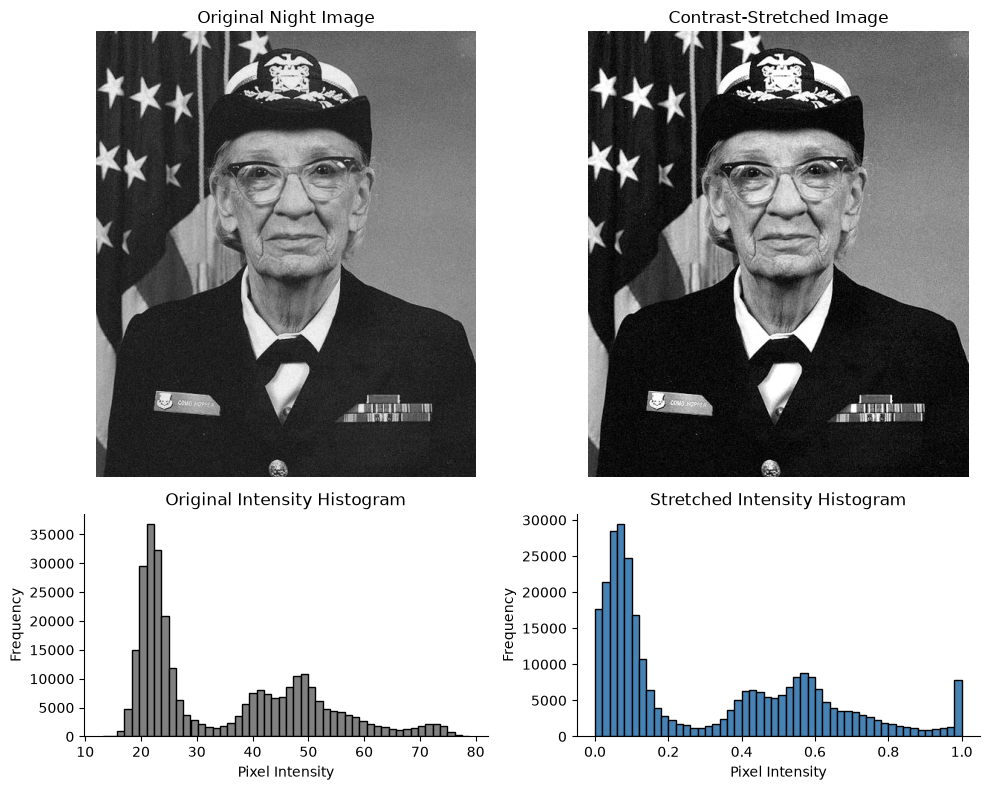

Contrast before: 0.591  ->  after: 1.000


In [9]:
import numpy as np
import matplotlib.pyplot as plt

def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: Robust Michelson contrast of night_still
# Use 2nd and 98th percentiles to avoid extreme pixel values
lmin, lmax = np.percentile(night_still, [2, 98])
c_before = michelson(lmax, lmin)

# TODO 3: Contrast-stretched version of night_still
stretched = np.clip(
    (night_still.astype(float) - lmin) / (lmax - lmin + 1e-10),
    0,
    1
)

# Calculate contrast after stretching
lmin_after, lmax_after = np.percentile(stretched, [2, 98])
c_after = michelson(lmax_after, lmin_after)

# TODO 1 & 4: Top row = images, bottom row = histograms
fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    gridspec_kw={"height_ratios": [2, 1]}
)

# Top-left: Original image
axes[0, 0].imshow(night_still, cmap="gray")
axes[0, 0].set_title("Original Night Image")
axes[0, 0].axis("off")

# Top-right: Contrast-stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=1)
axes[0, 1].set_title("Contrast-Stretched Image")
axes[0, 1].axis("off")

# Bottom-left: Original histogram
axes[1, 0].hist(
    night_still.ravel(),
    bins=50,
    color="gray",
    edgecolor="black"
)
axes[1, 0].set_title("Original Intensity Histogram")
axes[1, 0].set_xlabel("Pixel Intensity")
axes[1, 0].set_ylabel("Frequency")

# Bottom-right: Stretched histogram
axes[1, 1].hist(
    stretched.ravel(),
    bins=50,
    color="steelblue",
    edgecolor="black"
)
axes[1, 1].set_title("Stretched Intensity Histogram")
axes[1, 1].set_xlabel("Pixel Intensity")
axes[1, 1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_The night image's histogram is narrow and mostly towards the dark side because most pixels have low brightness. Stretching spreads out the brightness values, making the image clearer and easier to see. It doesn't add any new details, it just makes the existing details more visible. A histogram only shows how many pixels have each brightness value, not where they are, so we can't tell what objects are in the image.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Person speed calculated (px/s)
count    1380.000000
mean       35.425628
std        21.219354
min         0.000000
25%        20.144757
50%        31.258403
75%        46.619143
max       150.150150
Name: person_speed, dtype: float64

Standing time ranges:
40.97s to 40.97s
42.53s to 42.53s
42.87s to 42.90s
50.33s to 50.33s
50.47s to 50.47s
51.33s to 51.33s
54.50s to 54.50s
55.33s to 55.33s
58.73s to 58.73s
59.70s to 59.70s
59.93s to 59.93s
60.80s to 60.80s
60.97s to 60.97s
63.63s to 63.63s
64.70s to 64.70s
65.17s to 65.17s
67.57s to 67.57s
69.17s to 69.17s
69.30s to 69.30s
70.07s to 70.07s
72.87s to 72.87s
80.83s to 80.83s
85.90s to 85.90s

Running time ranges:
40.60s to 40.60s
40.67s to 40.67s
40.93s to 40.93s
41.70s to 41.77s
41.83s to 41.83s
43.20s to 43.20s
43.60s to 43.63s
44.67s to 44.67s
45.07s to 45.07s
45.53s to 45.57s
45.87s to 45.87s
46.23s to 46.23s
46.47s to 46.47s
46.97s to 46.97s
47.40s to 47.40s
47.87s to 47.87s
48.10s to 48.10s
48.53s to 48.57s
48.77s to 48.77s
49.27s 

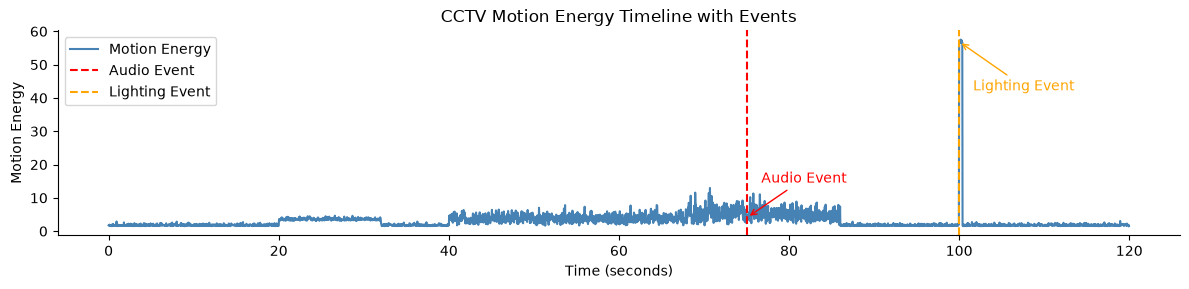

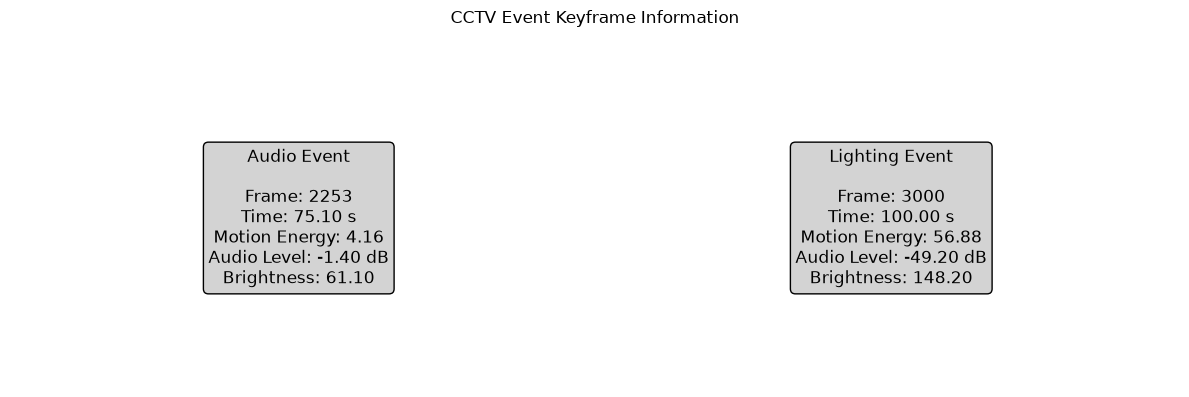

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")

# TODO 1: Person speed (px/s)
dt = cctv["time_s"].diff()
dx = cctv["person_x"].diff()
dy = cctv["person_y"].diff()

speed = np.sqrt(dx**2 + dy**2) / dt

# Store speed in dataframe
cctv["person_speed"] = speed

print("Person speed calculated (px/s)")
print(cctv["person_speed"].describe())


# TODO 2: Standing / running time ranges

# Classify movement based on speed
standing_mask = speed < 5
running_mask = speed > 50

def get_time_ranges(mask, times):
    mask = mask.fillna(False).to_numpy()
    times = times.to_numpy()

    changes = np.diff(np.r_[False, mask, False].astype(int))
    starts = np.where(changes == 1)[0]
    ends = np.where(changes == -1)[0] - 1

    return [(times[s], times[e]) for s, e in zip(starts, ends)]

standing_ranges = get_time_ranges(standing_mask, cctv["time_s"])
running_ranges = get_time_ranges(running_mask, cctv["time_s"])

print("\nStanding time ranges:")
for start, end in standing_ranges:
    print(f"{start:.2f}s to {end:.2f}s")

print("\nRunning time ranges:")
for start, end in running_ranges:
    print(f"{start:.2f}s to {end:.2f}s")


# TODO 3: Event frame indices

# Audio event: highest audio level
audio_event_idx = int(cctv["audio_level_db"].idxmax())

# Lighting event: largest sudden brightness change
lighting_event_idx = int(
    cctv["mean_brightness"].diff().abs().idxmax()
)

print("\nAudio event frame:", audio_event_idx)
print("Lighting event frame:", lighting_event_idx)


# TODO 4: Annotated motion-energy timeline

fig, ax = plt.subplots(figsize=(12, 3))

ax.plot(
    cctv["time_s"],
    cctv["motion_energy"],
    color="steelblue",
    label="Motion Energy"
)

audio_time = cctv.loc[audio_event_idx, "time_s"]
lighting_time = cctv.loc[lighting_event_idx, "time_s"]

ax.axvline(
    audio_time,
    color="red",
    linestyle="--",
    label="Audio Event"
)

ax.axvline(
    lighting_time,
    color="orange",
    linestyle="--",
    label="Lighting Event"
)

ax.annotate(
    "Audio Event",
    xy=(audio_time, cctv.loc[audio_event_idx, "motion_energy"]),
    xytext=(10, 25),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="red"),
    color="red"
)

ax.annotate(
    "Lighting Event",
    xy=(lighting_time, cctv.loc[lighting_event_idx, "motion_energy"]),
    xytext=(10, -35),
    textcoords="offset points",
    arrowprops=dict(arrowstyle="->", color="orange"),
    color="orange"
)

ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.set_title("CCTV Motion Energy Timeline with Events")
ax.legend()

plt.tight_layout()
plt.show()


# TODO 5: One keyframe per event

# Display event details
events = {
    "Audio Event": audio_event_idx,
    "Lighting Event": lighting_event_idx
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (event_name, idx) in zip(axes, events.items()):

    # Display available frame information
    event = cctv.loc[idx]

    ax.axis("off")

    info = (
        f"{event_name}\n\n"
        f"Frame: {int(event['frame'])}\n"
        f"Time: {event['time_s']:.2f} s\n"
        f"Motion Energy: {event['motion_energy']:.2f}\n"
        f"Audio Level: {event['audio_level_db']:.2f} dB\n"
        f"Brightness: {event['mean_brightness']:.2f}"
    )

    ax.text(
        0.5, 0.5,
        info,
        ha="center",
        va="center",
        fontsize=12,
        bbox=dict(boxstyle="round", facecolor="lightgray")
    )

plt.suptitle("CCTV Event Keyframe Information")
plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_Using one keyframe every 20 seconds could miss sudden events like the loud sound or sudden lighting change because they happen very quickly. Instead, we used **event-based keyframe selection**, where frames are selected when something important happens.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

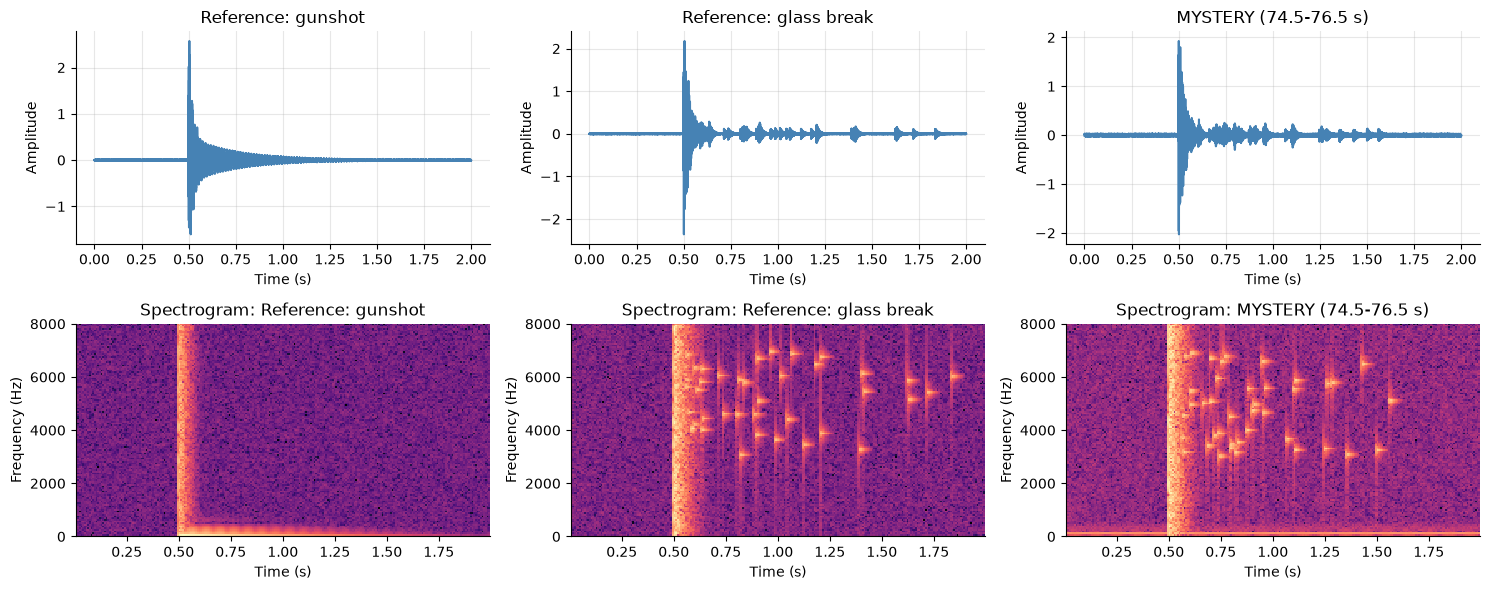

High-frequency energy fraction (>3 kHz):
Reference: gunshot: 0.0031
Reference: glass break: 0.9905
MYSTERY (74.5-76.5 s): 0.8785

--- AUDIO FORENSICS VERDICT ---
Mystery high-frequency fraction: 0.8785
Gunshot reference difference: 0.8754
Glass reference difference: 0.1119
Most similar reference: GLASS BREAK
Note: This is a preliminary classification based on one spectral feature.


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# --- Prepare audio clips ---
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]

clips = {
    "Reference: gunshot": ref_gunshot[1],
    "Reference: glass break": ref_glass[1],
    "MYSTERY (74.5-76.5 s)": mystery
}

# Sampling frequency
fs = 16000

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

# TODO 1 & 2: Waveform (top row) and spectrogram (bottom row)
for i, (name, clip) in enumerate(clips.items()):

    clip = np.asarray(clip)

    # Waveform
    time = np.arange(len(clip)) / fs

    axes[0, i].plot(time, clip, color="steelblue")
    axes[0, i].set_title(name)
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")
    axes[0, i].grid(alpha=0.3)

    # Spectrogram
    frequencies, times, Sxx = spectrogram(
        clip,
        fs=fs,
        nperseg=256,
        noverlap=128
    )

    axes[1, i].pcolormesh(
        times,
        frequencies,
        10 * np.log10(Sxx + 1e-12),
        shading="auto",
        cmap="magma"
    )

    axes[1, i].set_title(f"Spectrogram: {name}")
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_ylim(0, 8000)

plt.tight_layout()
plt.show()


# TODO 3: Fraction of energy above 3 kHz
# Analyze 0.2–1.2 seconds AFTER impact at t = 0.5 s
# Therefore, analyze t = 0.7 to 1.7 seconds

hf_fraction = {}

for name, clip in clips.items():

    clip = np.asarray(clip)

    start = int(0.7 * fs)
    end = int(1.7 * fs)

    segment = clip[start:end]

    # FFT
    fft_values = np.fft.rfft(segment)
    frequencies = np.fft.rfftfreq(len(segment), d=1/fs)

    # Spectral energy
    energy = np.abs(fft_values) ** 2

    total_energy = np.sum(energy)
    high_frequency_energy = np.sum(
        energy[frequencies > 3000]
    )

    hf_fraction[name] = (
        high_frequency_energy / total_energy
        if total_energy > 0 else 0
    )

print("High-frequency energy fraction (>3 kHz):")

for name, fraction in hf_fraction.items():
    print(f"{name}: {fraction:.4f}")


# TODO 4: Verdict
gunshot_fraction = hf_fraction["Reference: gunshot"]
glass_fraction = hf_fraction["Reference: glass break"]
mystery_fraction = hf_fraction["MYSTERY (74.5-76.5 s)"]

gunshot_difference = abs(mystery_fraction - gunshot_fraction)
glass_difference = abs(mystery_fraction - glass_fraction)

if gunshot_difference < glass_difference:
    verdict = "GUNSHOT"
else:
    verdict = "GLASS BREAK"

print("\n--- AUDIO FORENSICS VERDICT ---")
print(f"Mystery high-frequency fraction: {mystery_fraction:.4f}")
print(f"Gunshot reference difference: {gunshot_difference:.4f}")
print(f"Glass reference difference: {glass_difference:.4f}")
print(f"Most similar reference: {verdict}")
print("Note: This is a preliminary classification based on one spectral feature.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_No, just by looking at the waveforms, it was difficult to tell the difference because both had sudden loud sounds. The spectrogram shows three things: time, frequency and intensity (colour). A gunshot usually shows a vertical stripe, while glass breaking has scattered high-frequency specks. These patterns help us identify the sound more clearly.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

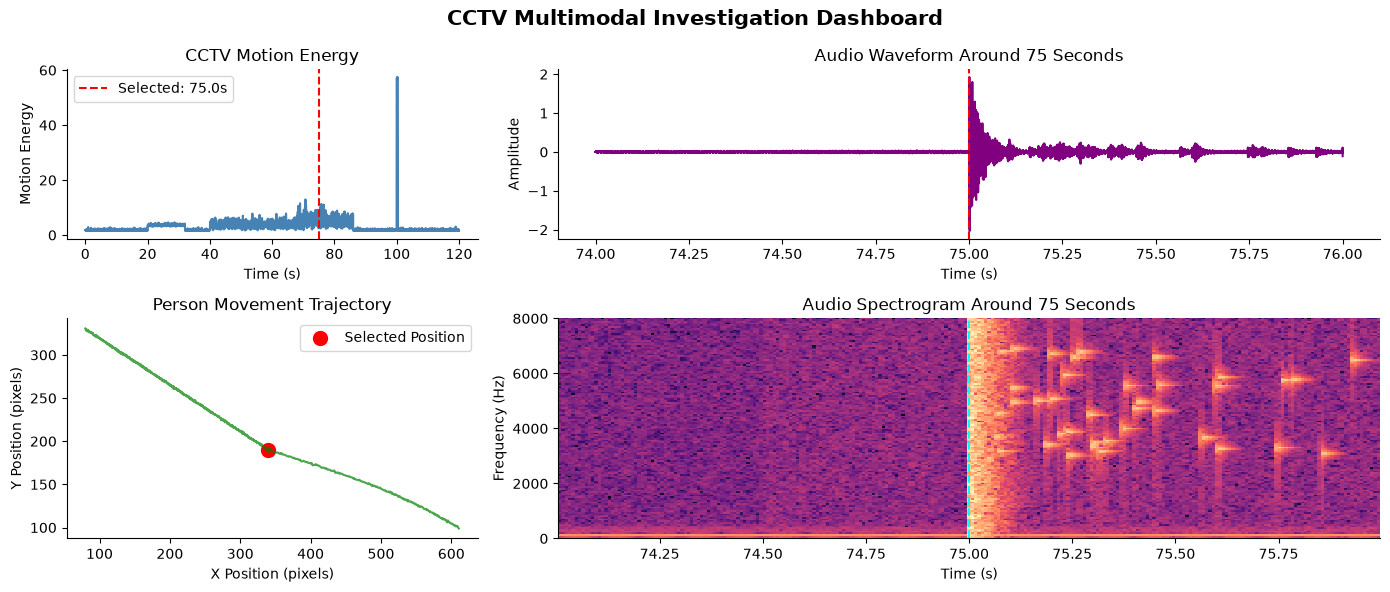

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# Selected investigation time
t_sel = 75.0

# Load CCTV data
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")

# Audio sampling rate
fs = 16000

fig = plt.figure(figsize=(14, 6))

gs = fig.add_gridspec(
    2, 2,
    width_ratios=[1, 2],
    height_ratios=[1, 1.3]
)

# TODO 1: Motion energy timeline
ax1 = fig.add_subplot(gs[0, 0])

ax1.plot(
    cctv["time_s"],
    cctv["motion_energy"],
    color="steelblue"
)

ax1.axvline(
    t_sel,
    color="red",
    linestyle="--",
    label=f"Selected: {t_sel}s"
)

ax1.set_title("CCTV Motion Energy")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Motion Energy")
ax1.legend()


# TODO 2: Person movement trajectory
ax2 = fig.add_subplot(gs[1, 0])

person_data = cctv.dropna(
    subset=["person_x", "person_y"]
)

ax2.plot(
    person_data["person_x"],
    person_data["person_y"],
    color="green",
    alpha=0.7
)

# Highlight person position near selected time
if not person_data.empty:
    nearest_idx = (
        person_data["time_s"] - t_sel
    ).abs().idxmin()

    selected_person = person_data.loc[nearest_idx]

    ax2.scatter(
        selected_person["person_x"],
        selected_person["person_y"],
        color="red",
        s=100,
        label="Selected Position"
    )

ax2.set_title("Person Movement Trajectory")
ax2.set_xlabel("X Position (pixels)")
ax2.set_ylabel("Y Position (pixels)")
ax2.legend()


# TODO 3: Audio waveform near selected time
ax3 = fig.add_subplot(gs[0, 1])

audio_mask = (
    (t_audio >= t_sel - 1) &
    (t_audio <= t_sel + 1)
)

audio_clip = x_audio[audio_mask]
audio_times = t_audio[audio_mask]

ax3.plot(
    audio_times,
    audio_clip,
    color="purple"
)

ax3.axvline(
    t_sel,
    color="red",
    linestyle="--"
)

ax3.set_title("Audio Waveform Around 75 Seconds")
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Amplitude")


# TODO 4: Audio spectrogram
ax4 = fig.add_subplot(gs[1, 1])

if len(audio_clip) >= 256:

    frequencies, times, Sxx = spectrogram(
        audio_clip,
        fs=fs,
        nperseg=256,
        noverlap=128
    )

    ax4.pcolormesh(
        times + audio_times[0],
        frequencies,
        10 * np.log10(Sxx + 1e-12),
        shading="auto",
        cmap="magma"
    )

    ax4.axvline(
        t_sel,
        color="cyan",
        linestyle="--"
    )

ax4.set_title("Audio Spectrogram Around 75 Seconds")
ax4.set_xlabel("Time (s)")
ax4.set_ylabel("Frequency (Hz)")
ax4.set_ylim(0, 8000)

fig.suptitle(
    "CCTV Multimodal Investigation Dashboard",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_If the audio was delayed by 2 seconds, the sound would not match what was happening in the video. This could make us misunderstand when an event actually happened. The audio waveform and spectrogram panels would help us notice the mistake by comparing the sound timing with the video events.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_In Lot B, suspicious movement was detected around [time], followed by a sudden loud sound at [time] and a change in lighting at [time]. I would show the synchronized view first because it helps us see the video and audio events together. This follows the lecture idea of understanding patterns, changes and events to find their meaning. For storage, I would recommend keeping the original footage for important events and using 360p/10 fps for normal footage to save space. We should not lose important evidence like the exact moment of the sudden sound and movement.